In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import numpy as np

In [7]:
processed_data_dir =  'data/processed/image_tagging'
images_dir = 'data/raw/source_a_synthetic/warehouse_detection_dataset/yolo/images'


train_df = pd.read_csv(os.path.join(processed_data_dir, 'train_tags.csv'))
val_df = pd.read_csv(os.path.join(processed_data_dir, 'val_tags.csv'))
test_df = pd.read_csv(os.path.join(processed_data_dir, 'test_tags.csv'))


print(f"Train samples: {len(train_df)}")
print(f"Val samples: {len(val_df)}")
print(f"Test samples: {len(test_df)}")

train_df.head()

Train samples: 4654
Val samples: 1125
Test samples: 1124


,image_filename,tags,box,crate,barrel,bottle,pallet,rack,bracket,lamp,...,ceiling,floor,pillar,forklift,bucket,cone,cart,emergency_board,paper_note,paper_shortcut
0,warehouse_013055.png,"box,pallet,rack,bracket,sign,floor_decal,wall,...",1,0,0,0,1,1,1,0,...,0,1,1,0,0,0,0,0,0,0
1,warehouse_013187.png,"box,pallet,rack,bracket,sign,floor_decal,wall,...",1,0,0,0,1,1,1,0,...,0,1,1,0,0,0,0,0,0,0
2,warehouse_012337.png,"box,pallet,rack,bracket,lamp,sign,floor_decal,...",1,0,0,0,1,1,1,1,...,0,1,1,0,0,0,0,0,1,0
3,warehouse_002569.png,"box,pallet,rack,sign,wire,fuse_box,floor_decal...",1,0,0,0,1,1,0,0,...,0,1,0,0,0,0,0,0,0,0
4,warehouse_002597.png,"box,pallet,rack,bracket,lamp,sign,wire,floor_d...",1,0,0,0,1,1,1,1,...,1,1,1,1,0,0,0,0,1,0


/tmp/ipykernel_173839/3476423827.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')


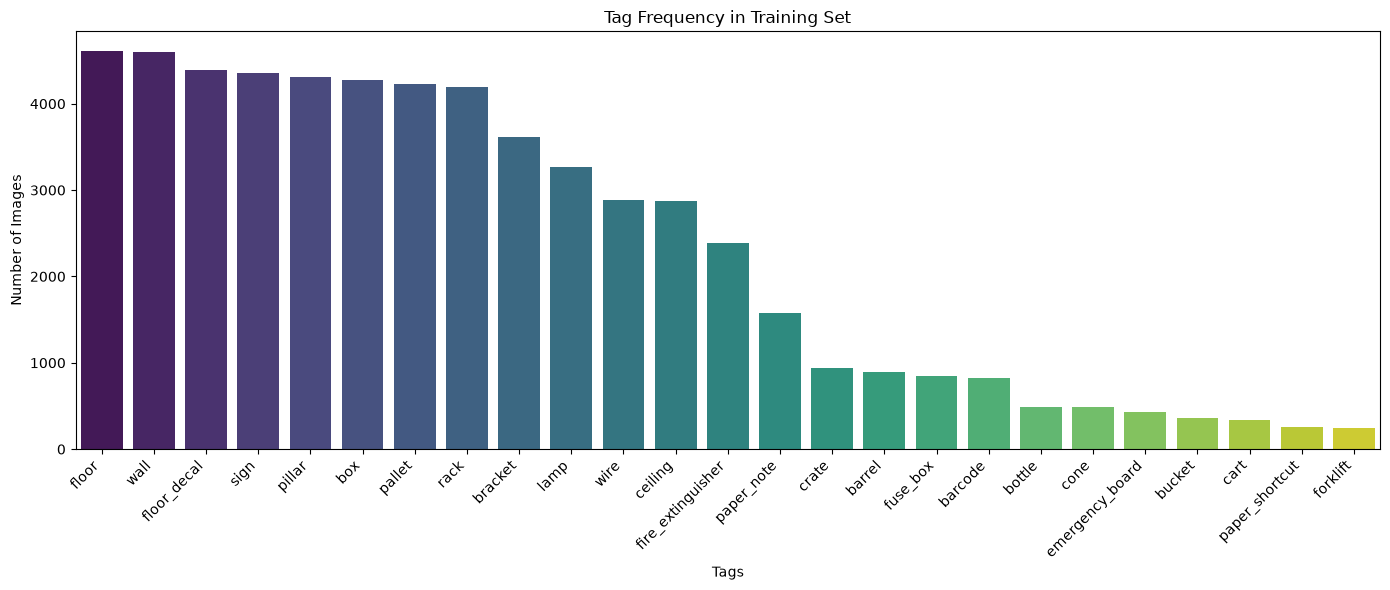

In [8]:
# Get all class columns (skip 'image_filename' and 'tags')
class_columns = train_df.columns[2:]

# Calculate the frequency of each class in the training set
class_counts = train_df[class_columns].sum().sort_values(ascending=False)

plt.figure(figsize=(14, 6))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='viridis')
plt.title('Tag Frequency in Training Set')
plt.xlabel('Tags')
plt.ylabel('Number of Images')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


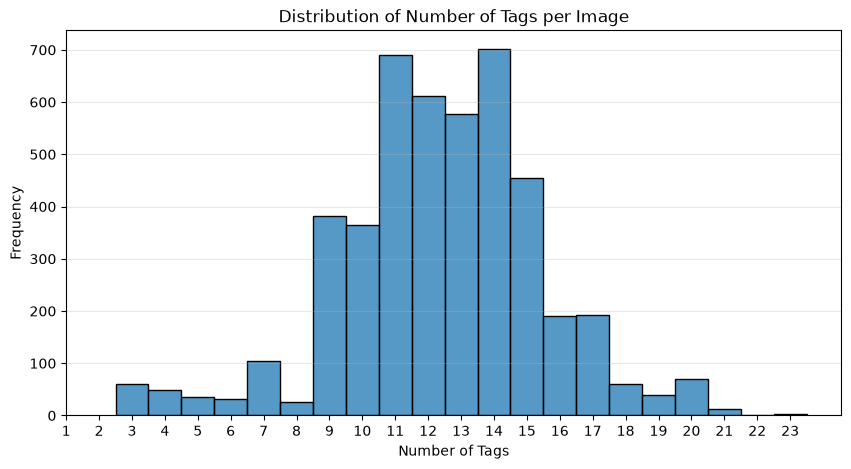

In [9]:
# Calculate how many tags each image has
train_df['num_tags'] = train_df[class_columns].sum(axis=1)

plt.figure(figsize=(10, 5))
sns.histplot(train_df['num_tags'], bins=range(1, int(train_df['num_tags'].max()) + 2), discrete=True)
plt.title('Distribution of Number of Tags per Image')
plt.xlabel('Number of Tags')
plt.ylabel('Frequency')
plt.xticks(range(1, int(train_df['num_tags'].max()) + 1))
plt.grid(axis='y', alpha=0.3)
plt.show()


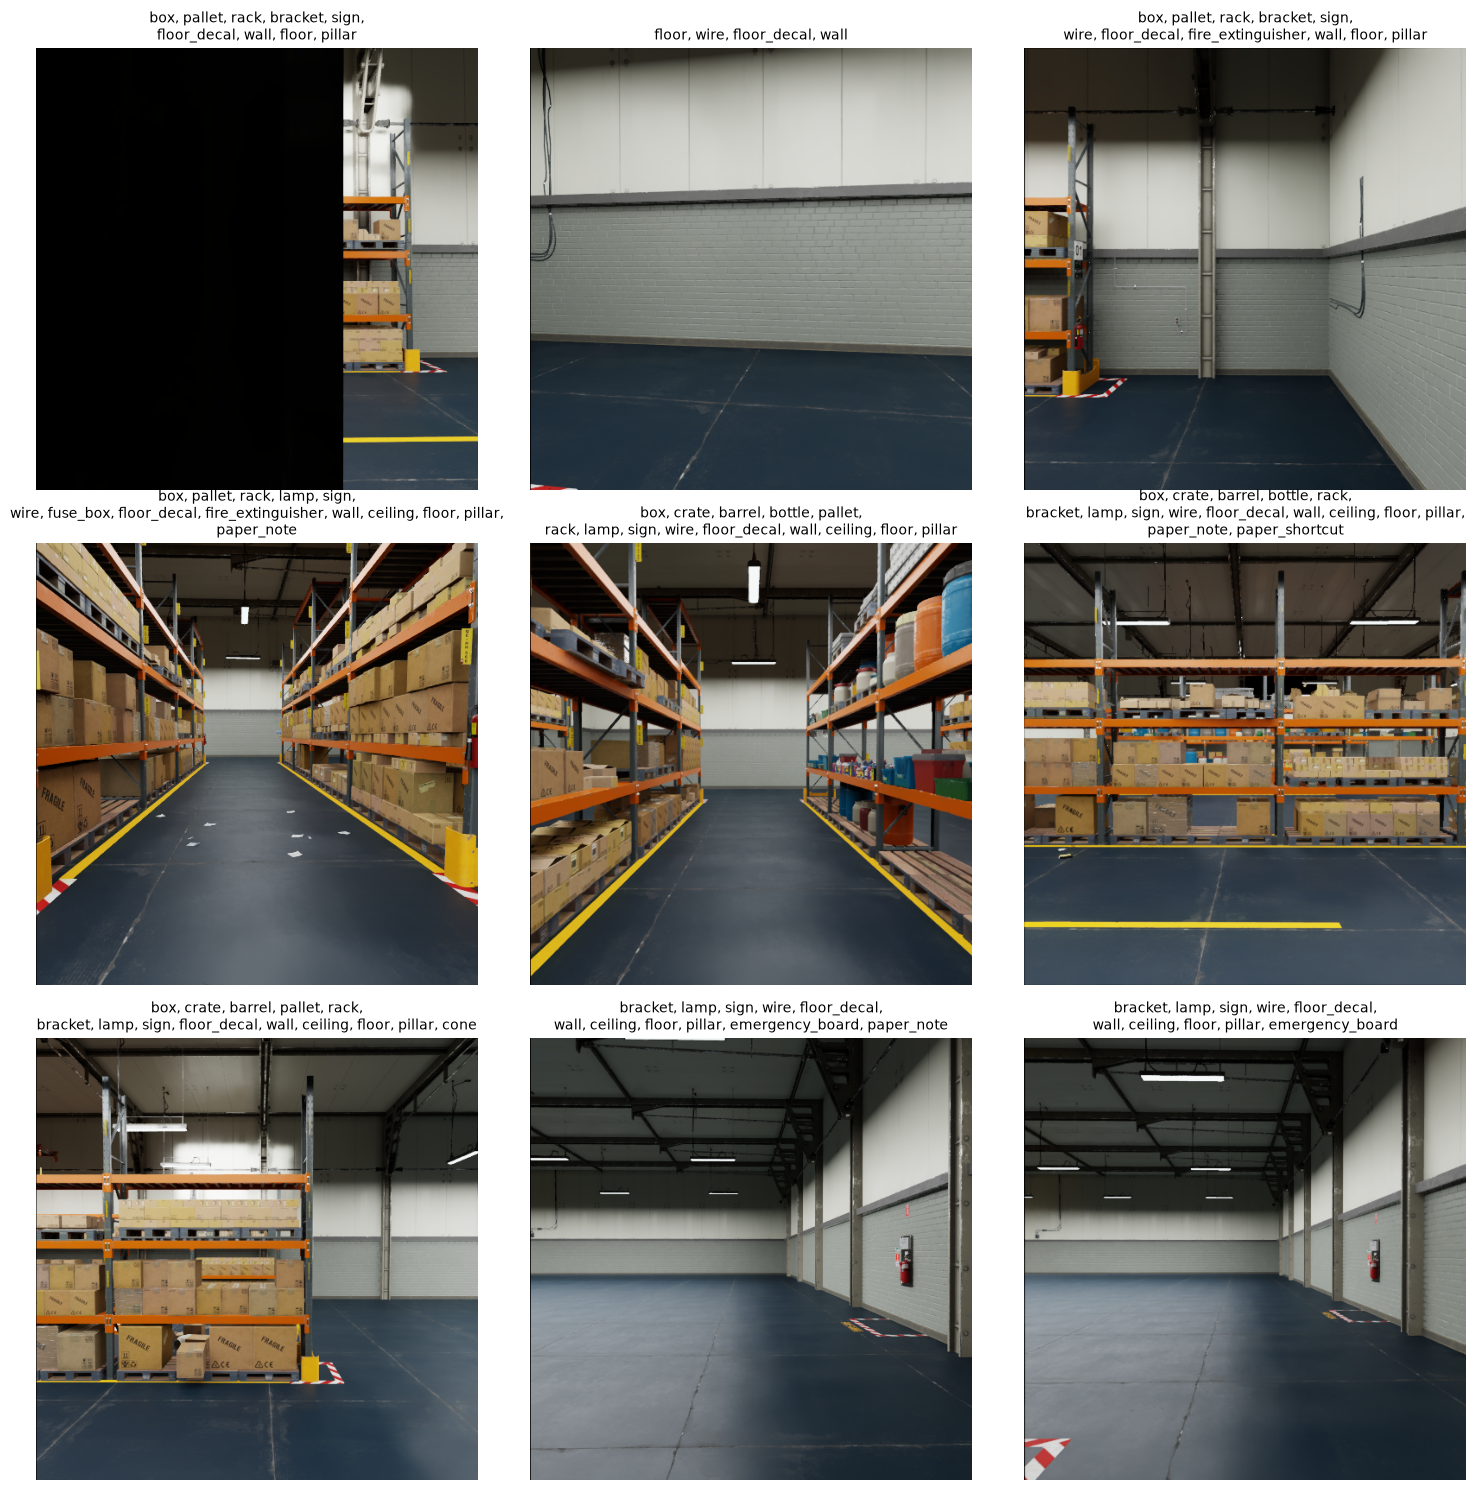

In [11]:
# Set up a 3x3 grid for image visualization
fig, axes = plt.subplots(3, 3, figsize=(15, 15))
axes = axes.flatten()

# Sample 9 random images from the training dataframe
sample_df = train_df.sample(9, random_state=42)

for i, (_, row) in enumerate(sample_df.iterrows()):
    img_filename = row['image_filename']
    tags_string = row['tags']
    
    # YOLO structure separates images by train/val/test
    img_path = os.path.join(images_dir, 'train', img_filename)
    
    try:
        img = Image.open(img_path)
        axes[i].imshow(img)
        axes[i].axis('off')
        
        # Format tags nicely for the title (wrap if too long)
        tags_list = tags_string.split(',')
        if len(tags_list) > 5:
            display_tags = ', '.join(tags_list[:5]) + ',\n' + ', '.join(tags_list[5:])
        else:
            display_tags = ', '.join(tags_list)
            
        axes[i].set_title(display_tags, fontsize=10, wrap=True)
    except FileNotFoundError:
        axes[i].set_title(f"Image not found:\n{img_filename}")
        axes[i].axis('off')

plt.tight_layout()
plt.show()


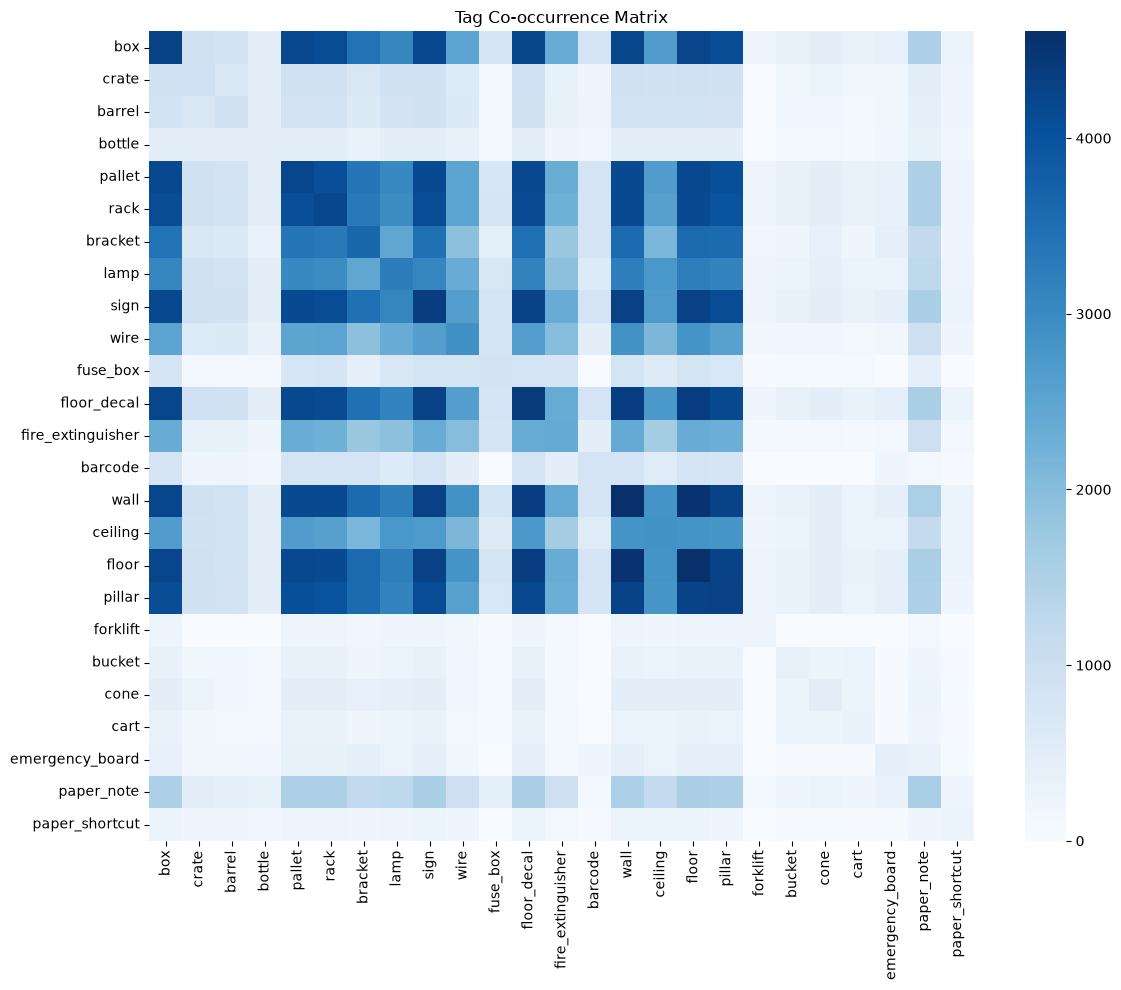

In [12]:
# Create a co-occurrence matrix
co_occurrence = train_df[class_columns].T.dot(train_df[class_columns])

plt.figure(figsize=(12, 10))
sns.heatmap(co_occurrence, cmap='Blues', annot=False, fmt='d')
plt.title('Tag Co-occurrence Matrix')
plt.tight_layout()
plt.show()


/tmp/ipykernel_173839/2312135440.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_combinations.index, x=top_combinations.values, palette='magma')


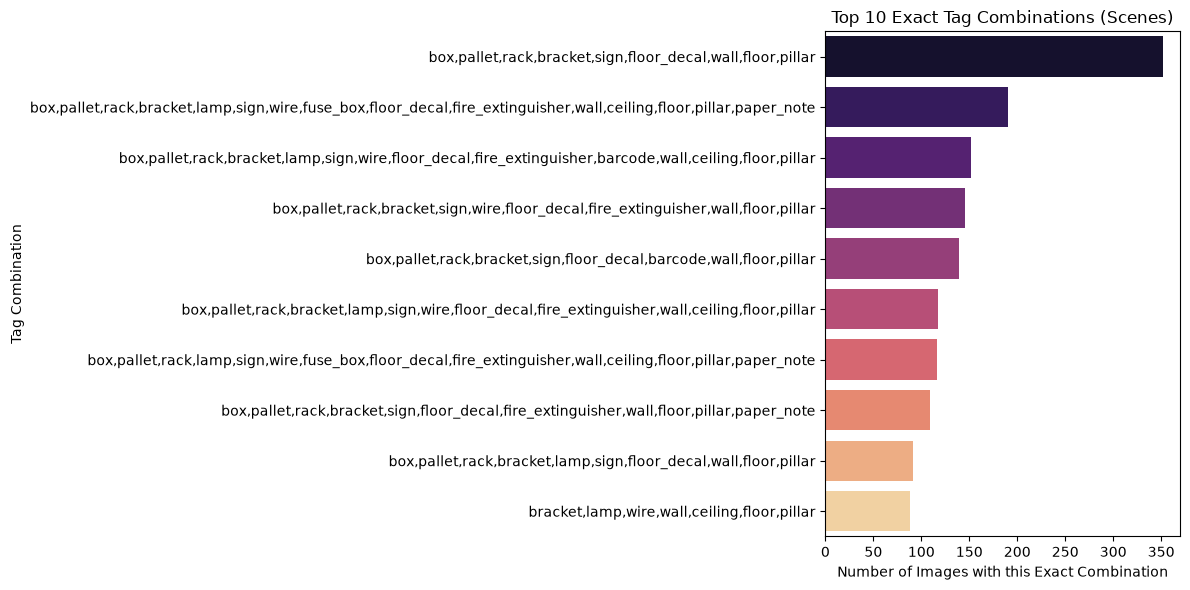

In [13]:
# Count the exact combinations of tags (the string representation)
top_combinations = train_df['tags'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(y=top_combinations.index, x=top_combinations.values, palette='magma')
plt.title('Top 10 Exact Tag Combinations (Scenes)')
plt.xlabel('Number of Images with this Exact Combination')
plt.ylabel('Tag Combination')
plt.tight_layout()
plt.show()


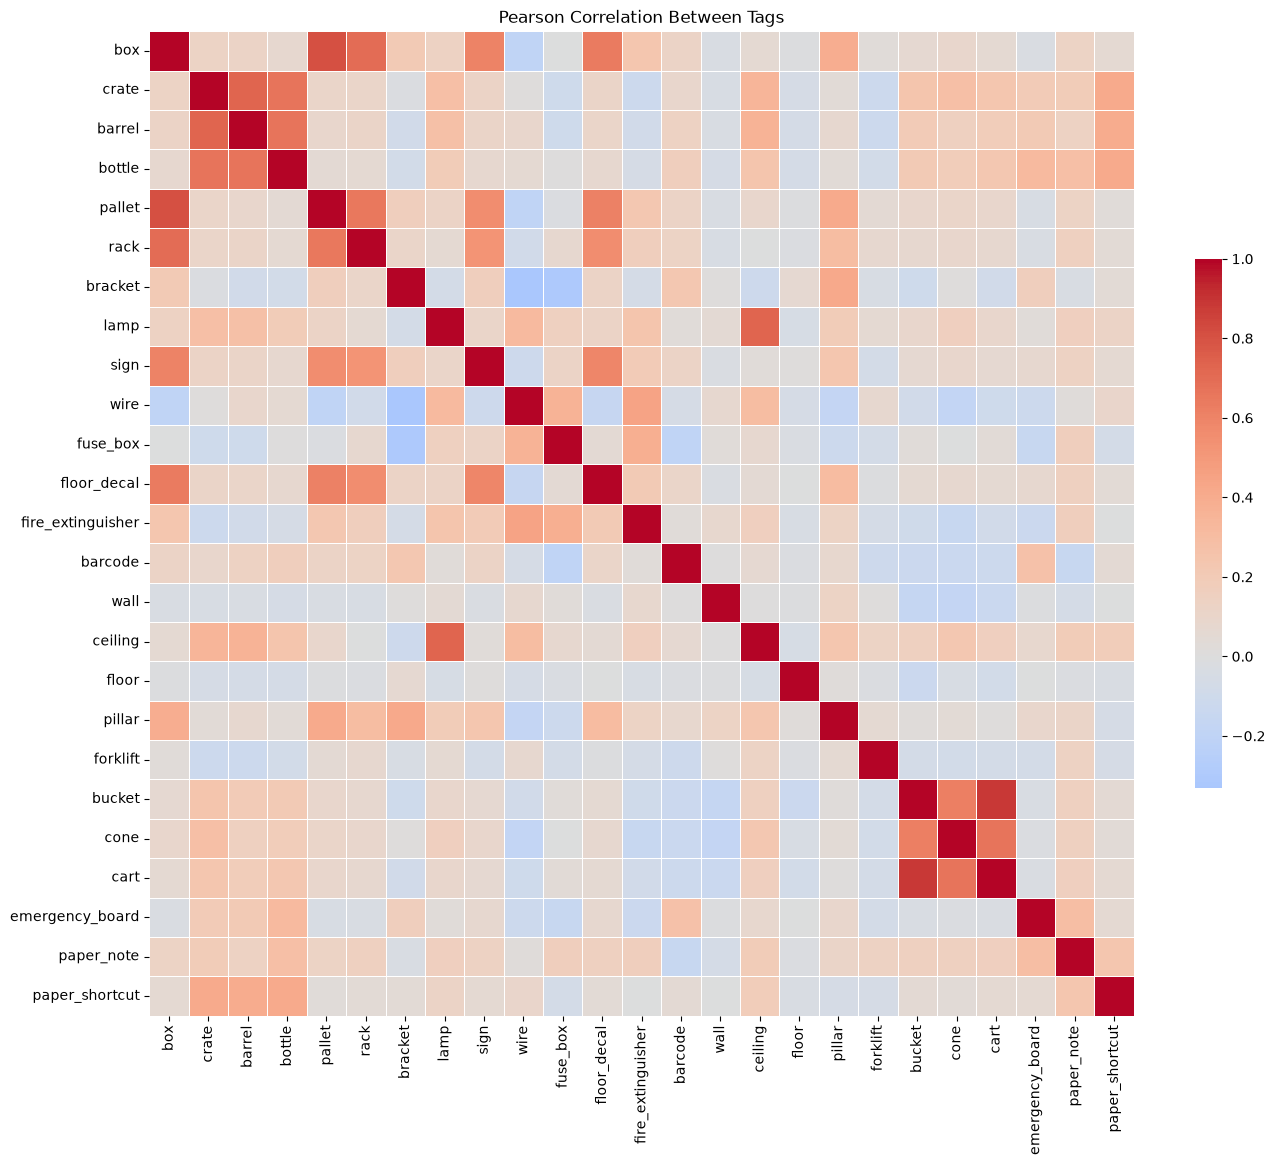

In [14]:
# Calculate Pearson correlation between classes
correlation_matrix = train_df[class_columns].corr()

plt.figure(figsize=(14, 12))
# Use a diverging colormap so 0 is white, positive is red, negative is blue
sns.heatmap(correlation_matrix, cmap='coolwarm', center=0, 
            annot=False, square=True, linewidths=.5, cbar_kws={"shrink": .5})
plt.title('Pearson Correlation Between Tags')
plt.tight_layout()
plt.show()
